# Speed Prediction — 파생/추가 피처 빠른 테스트 (LightGBM)

**목적**: `11_speed_model_baseline.ipynb`의 LightGBM 결과를 기준점으로 두고, 파생 피처와 신규 외부 피처를 추가했을 때 실제로 개선되는지 **LightGBM 하나로만** 빠르게 확인합니다.

**이번 버전(v2) 변경점**
- 버스전용차로: 1차 시도(30% 겹침 기준 boolean)의 gain 기여도가 0.17%로 낮았던 걸 보완하려고, 겹침 비율을 **연속값**(`bus_lane_ratio`, 0~1)으로 바꿔서 정보 손실을 줄였습니다.
- **추정교통량**(`TrafficVolume(LINK) (1).xlsx`, 2024년 평일 기준) 신규 추가: 링크별 시간대별 교통량(`traffic_volume_hourly`)과 연평균 일교통량(`traffic_volume_aadt`). `ITS LINK ID`가 우리 `LINK_ID`와 같은 체계라 조인 가능하지만, 콤마로 여러 LINK_ID가 묶인 셀(전체의 54%)이 있어 펼쳐서 매칭했습니다(펼친 후 44,960개 관측 링크 중 39.3% 커버 — 버스전용차로의 5~8%보다 훨씬 넓음). 매칭 안 되는 링크는 NaN으로 두고 LightGBM의 기본 결측치 처리에 맡깁니다(0으로 채우면 "교통량 없음"으로 잘못 해석될 수 있어서).

**비교 기준점(재실행 없이 인용)**

| model | rmse | mae | r2 |
| --- | --- | --- | --- |
| LightGBM (11번, 원본 피처) | 7.653 | 5.765 | 0.610 |
| LightGBM (1차: +파생/버스전용차로 boolean) | 7.629 | 5.747 | 0.613 |

**캐싱**: 피처 정의가 바뀌어서 캐시 파일명을 `nb12_feature_cache_v2.parquet`로 새로 둡니다(구버전 캐시와 섞이지 않게).

In [1]:
from pathlib import Path

import geopandas as gpd
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
DOCS_FIGURES_DIR = PROJECT_ROOT / "docs" / "figures" / "model"
DOCS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = PROCESSED_DATA_DIR / "seoul_link_speed_dem_weather_merged.csv"
SEOUL_LINK_SHP = INTERIM_DIR / "seoul_link.shp"
BUS_LANE_SHP = RAW_DIR / "traffic" / "A058_L_20260213" / "A058_L" / "A058_L.shp"
TRAFFIC_VOLUME_XLSX = RAW_DIR / "traffic" / "TrafficVolume(LINK) (1).xlsx"
CACHE_PATH = INTERIM_DIR / "nb12_feature_cache_v2.parquet"

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42
COLOR_RMSE = "#2a78d6"   # dataviz 팔레트 slot 1 blue
COLOR_MAE = "#eb6834"    # dataviz 팔레트 slot 2 orange
COLOR_SEQ = "#3987e5"

BASELINE_11 = {"model": "LightGBM (11번, 원본 피처)", "rmse": 7.652966670997528, "mae": 5.764899686592482, "r2": 0.6101212805788272}
BASELINE_V1 = {"model": "LightGBM (1차: +파생/버스전용차로 boolean)", "rmse": 7.629313, "mae": 5.747021, "r2": 0.612528}


## 1. 버스전용차로 겹침 비율 (연속값으로 개선)

1차 시도에서 30% 겹침 여부만 boolean으로 넣었더니 gain 기여도가 0.17%로 낮았습니다. 겹침 비율 자체(0~1 연속값)를 그대로 넣으면 "얼마나 겹치는지" 정보가 보존되어 트리가 더 세밀한 분기를 찾을 여지가 생깁니다.

In [2]:
seoul_link = gpd.read_file(SEOUL_LINK_SHP)
bus = gpd.read_file(BUS_LANE_SHP).to_crs(seoul_link.crs)

bus_buffer = bus.buffer(8).union_all()
overlap_len = seoul_link.geometry.intersection(bus_buffer).length
overlap_ratio = (overlap_len / seoul_link.geometry.length).clip(upper=1).fillna(0)

bus_lane_lookup = pd.DataFrame({
    "LINK_ID": seoul_link["LINK_ID"].astype(str),
    "bus_lane_ratio": overlap_ratio.astype("float32"),
})
print("겹침 비율 > 0인 링크 수:", (bus_lane_lookup["bus_lane_ratio"] > 0).sum(), "/", len(bus_lane_lookup))
print(bus_lane_lookup["bus_lane_ratio"].describe())


겹침 비율 > 0인 링크 수: 5011 / 63548
count    63548.000000
mean         0.049993
std          0.202863
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: bus_lane_ratio, dtype: float64


## 2. 추정교통량 (신규)

`TrafficVolume(LINK) (1).xlsx`는 Level 5.5(주요도로망) 링크 단위 2024년 평일 추정교통량입니다. `ITS LINK ID` 컬럼이 우리 `LINK_ID`와 같은 체계지만, 굵은 구간 하나가 여러 세부 링크를 포함해서 콤마로 여러 ID가 묶인 셀이 있습니다 — 펼쳐서(explode) 매칭합니다.

시간대별 컬럼은 `0~1시`~`23~24시` 24개입니다. 우리 `시간코드`가 1~24 값이라, **시간코드 i = i번째 시간대 버킷(즉 시간코드 1 = 0~1시, 시간코드 24 = 23~24시)**으로 가정해 매칭합니다(공식 문서로 확인된 건 아니라 가정임을 표시해둡니다).

In [3]:
tv_col_names = [
    "LEVEL55_LINK_ID", "ITS_LINK_ID", "road_rank_tv", "road_name_tv", "region_tv",
    "length_km_tv", "lanes_tv", "aadt",
] + [f"vol_h{h}" for h in range(1, 25)]

tv = pd.read_excel(TRAFFIC_VOLUME_XLSX, sheet_name="Sheet0", header=6, skiprows=[7])
tv.columns = tv_col_names

tv["its_id_list"] = tv["ITS_LINK_ID"].astype(str).str.split(",")
tv_exp = tv.explode("its_id_list")
tv_exp["LINK_ID"] = tv_exp["its_id_list"].str.strip()
tv_exp = tv_exp[tv_exp["LINK_ID"] != "0"]  # 대응하는 ITS 링크가 없는 자리표시자(0) 제거

# 콤마로 묶인 구간이 겹쳐서 같은 LINK_ID가 여러 5.5 LINK ID 그룹에 속할 수 있어 평균으로 합침
aadt_lookup = tv_exp.groupby("LINK_ID", as_index=False)["aadt"].mean().rename(columns={"aadt": "traffic_volume_aadt"})

hourly_cols = [f"vol_h{h}" for h in range(1, 25)]
tv_long = tv_exp.melt(id_vars="LINK_ID", value_vars=hourly_cols, var_name="hour_col", value_name="traffic_volume_hourly")
tv_long["시간코드"] = tv_long["hour_col"].str.replace("vol_h", "", regex=False).astype("float32")
tv_long = tv_long.groupby(["LINK_ID", "시간코드"], as_index=False)["traffic_volume_hourly"].mean()

print("AADT 매칭 링크 수:", aadt_lookup["LINK_ID"].nunique())
print("시간대별 교통량 행 수:", len(tv_long), "(링크 수 x 24시간)")


C:\Users\ejjun\AppData\Roaming\Python\Python313\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


AADT 매칭 링크 수: 18164
시간대별 교통량 행 수: 435936 (링크 수 x 24시간)


## 3. 데이터 로드 (+ 캐싱)

In [4]:
NUMERIC_COLS = [
    "LANES", "MAX_SPD", "LENGTH", "시간코드",
    "elev_start_m", "elev_mid_m", "elev_end_m", "elev_mean_m", "elev_min_m", "elev_max_m", "elev_delta_m",
    "slope_pct", "abs_slope_pct", "precip_mm",
]
CATEGORICAL_COLS = [
    "ROAD_RANK", "ROAD_TYPE", "ROAD_USE", "MULTI_LINK", "CONNECT",
    "REST_VEH", "REST_W", "REST_H", "C-ITS",
]
# 결측이 정상인 컬럼(전체 매칭 안 됨) — NUMERIC_COLS의 dropna 대상에서 제외하고 LightGBM 기본 결측치 처리에 맡김
SPARSE_NUMERIC_COLS = ["traffic_volume_aadt", "traffic_volume_hourly"]
TARGET = "평균속도"

if CACHE_PATH.exists():
    df = pd.read_parquet(CACHE_PATH)
    print("캐시에서 로드:", CACHE_PATH)
else:
    usecols = NUMERIC_COLS + CATEGORICAL_COLS + [TARGET, "LINK_ID", "기준일"]
    dtype_map = {col: str for col in CATEGORICAL_COLS}
    dtype_map["LINK_ID"] = str
    dtype_map["기준일"] = str

    df = pd.read_csv(INPUT_PATH, usecols=usecols, dtype=dtype_map, encoding="utf-8-sig")

    for col in NUMERIC_COLS + [TARGET]:
        df[col] = pd.to_numeric(df[col], errors="coerce").astype("float32")

    df = df.merge(bus_lane_lookup, on="LINK_ID", how="left")
    df["bus_lane_ratio"] = df["bus_lane_ratio"].fillna(0).astype("float32")

    df = df.merge(aadt_lookup, on="LINK_ID", how="left")
    df = df.merge(tv_long, on=["LINK_ID", "시간코드"], how="left")

    RENAME_MAP = {"C-ITS": "c_its"}
    df = df.rename(columns=RENAME_MAP)
    CATEGORICAL_COLS = [RENAME_MAP.get(c, c) for c in CATEGORICAL_COLS]

    df = df.dropna(subset=[TARGET] + NUMERIC_COLS)
    df.to_parquet(CACHE_PATH)
    print("새로 만들어서 캐시 저장:", CACHE_PATH)

CATEGORICAL_COLS = [c if c != "C-ITS" else "c_its" for c in CATEGORICAL_COLS]
for col in CATEGORICAL_COLS:
    df[col] = df[col].astype("category")

print("행 수:", len(df), "| 컬럼 수:", df.shape[1])
print("메모리 사용량(MB):", round(df.memory_usage(deep=True).sum() / 1e6, 1))
print()
print("traffic_volume_hourly 결측 비율:", round(df["traffic_volume_hourly"].isna().mean() * 100, 1), "%")
print("traffic_volume_aadt 결측 비율:", round(df["traffic_volume_aadt"].isna().mean() * 100, 1), "%")
df.head()


새로 만들어서 캐시 저장: C:\Users\ejjun\Desktop\seoul-eco-routing\data\interim\nb12_feature_cache_v2.parquet


행 수: 15094335 | 컬럼 수: 29
메모리 사용량(MB): 1856.6

traffic_volume_hourly 결측 비율: 60.7 %
traffic_volume_aadt 결측 비율: 60.7 %


,LINK_ID,기준일,시간코드,평균속도,LANES,ROAD_RANK,ROAD_TYPE,ROAD_USE,MULTI_LINK,CONNECT,...,elev_mean_m,elev_min_m,elev_max_m,elev_delta_m,slope_pct,abs_slope_pct,precip_mm,bus_lane_ratio,traffic_volume_aadt,traffic_volume_hourly
0,1000000301,20260707,1.0,13.166667,2.0,103,0,0,1,0,...,29.623407,29.623407,29.623407,0.0,0.0,0.0,0.0,0.785023,19985.0,398.0
1,1000000301,20260707,2.0,16.250000,2.0,103,0,0,1,0,...,29.623407,29.623407,29.623407,0.0,0.0,0.0,0.0,0.785023,19985.0,317.0
2,1000000301,20260707,3.0,14.000000,2.0,103,0,0,1,0,...,29.623407,29.623407,29.623407,0.0,0.0,0.0,0.0,0.785023,19985.0,213.0
3,1000000301,20260707,4.0,15.000000,2.0,103,0,0,1,0,...,29.623407,29.623407,29.623407,0.0,0.0,0.0,0.0,0.785023,19985.0,180.0
4,1000000301,20260707,5.0,15.250000,2.0,103,0,0,1,0,...,29.623407,29.623407,29.623407,0.0,0.0,0.0,0.0,0.785023,19985.0,255.0


## 4. 파생 피처 생성 (요일/주말/시간 순환 인코딩)

캐시 이후 단계라 로직을 바꿔도 캐시 무효화가 필요 없습니다.

In [5]:
df["_date"] = pd.to_datetime(df["기준일"], format="%Y%m%d")
df["dow"] = df["_date"].dt.weekday.astype("category")
df["is_weekend"] = (df["_date"].dt.weekday >= 5).astype("int8")

hour = df["시간코드"].astype("float32")
df["hour_sin"] = np.sin(2 * np.pi * hour / 24).astype("float32")
df["hour_cos"] = np.cos(2 * np.pi * hour / 24).astype("float32")

df = df.drop(columns=["_date"])

DERIVED_COLS = ["dow", "is_weekend", "hour_sin", "hour_cos", "bus_lane_ratio"] + SPARSE_NUMERIC_COLS
df[DERIVED_COLS].describe(include="all")


,dow,is_weekend,hour_sin,hour_cos,bus_lane_ratio,traffic_volume_aadt,traffic_volume_hourly
count,15094335.0,1.509434e+07,1.509434e+07,1.509434e+07,1.509434e+07,5.938480e+06,5.938480e+06
unique,7.0,NaN,NaN,NaN,NaN,NaN,NaN
top,0.0,NaN,NaN,NaN,NaN,NaN,NaN
freq,2157217.0,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,2.857848e-01,-2.138451e-05,7.420300e-06,6.608189e-02,2.066972e+04,8.612402e+02
std,NaN,4.517874e-01,7.071058e-01,7.071078e-01,2.317023e-01,1.518205e+04,7.655930e+02
min,NaN,0.000000e+00,-1.000000e+00,-1.000000e+00,0.000000e+00,1.093000e+03,0.000000e+00
25%,NaN,0.000000e+00,-7.071067e-01,-7.071068e-01,0.000000e+00,1.115400e+04,3.570000e+02
50%,NaN,0.000000e+00,-8.742278e-08,1.192488e-08,0.000000e+00,1.748900e+04,6.600000e+02
75%,NaN,1.000000e+00,7.071068e-01,7.071070e-01,0.000000e+00,2.567400e+04,1.144000e+03


## 5. Train/Test 분할

11번과 동일하게 `random_state=42`, `test_size=0.2` 무작위 분할입니다.

In [6]:
FEATURE_COLS = NUMERIC_COLS + CATEGORICAL_COLS + DERIVED_COLS
X = df[FEATURE_COLS]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("train/test 행 수:", len(X_train), len(X_test))


train/test 행 수: 12075468 3018867


## 6. LightGBM 학습

베이스라인과 동일한 하이퍼파라미터를 씁니다.

In [7]:
def evaluate(y_true, y_pred, name):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"model": name, "rmse": rmse, "mae": mae, "r2": r2}


lgb_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=63,
    random_state=RANDOM_STATE,
    verbosity=-1,
)
lgb_model.fit(X_train, y_train, categorical_feature=CATEGORICAL_COLS + ["dow"])
pred = lgb_model.predict(X_test)

results_df = pd.DataFrame([BASELINE_11, BASELINE_V1, evaluate(y_test, pred, "LightGBM (2차: +비율/교통량)")])
results_df


,model,rmse,mae,r2
0,"LightGBM (11번, 원본 피처)",7.652967,5.764900,0.610121
1,LightGBM (1차: +파생/버스전용차로 boolean),7.629313,5.747021,0.612528
2,LightGBM (2차: +비율/교통량),7.508456,5.658695,0.624706


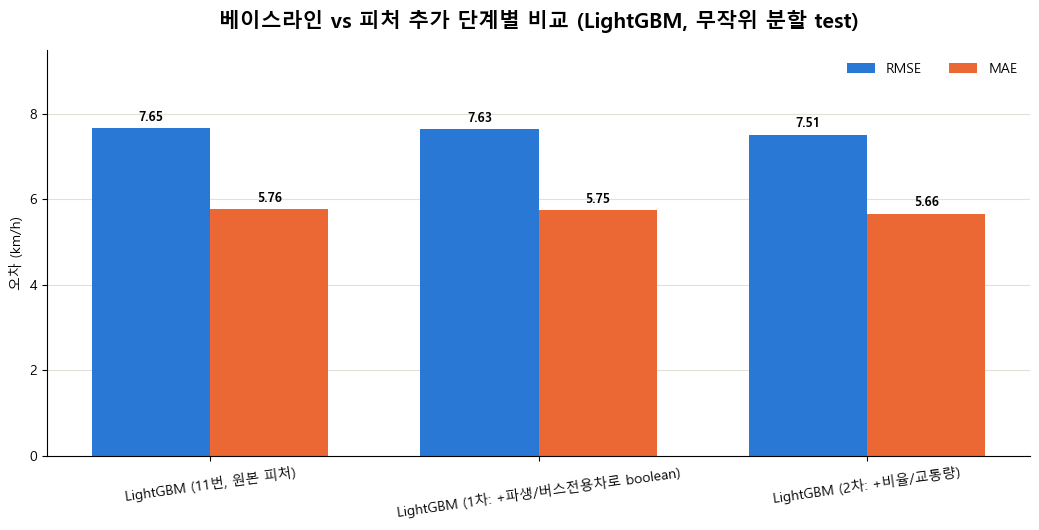

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\model\04_derived_features_comparison_v2.png


In [8]:
labels = results_df["model"].tolist()
x = range(len(labels))
width = 0.36

fig, ax = plt.subplots(figsize=(10.5, 5.4))
ax.bar([i - width / 2 for i in x], results_df["rmse"], width, label="RMSE", color=COLOR_RMSE)
ax.bar([i + width / 2 for i in x], results_df["mae"], width, label="MAE", color=COLOR_MAE)
ax.set_xticks(list(x), labels, rotation=8)
ax.set_title("베이스라인 vs 피처 추가 단계별 비교 (LightGBM, 무작위 분할 test)", fontsize=15, fontweight="bold", pad=16)
ax.set_ylabel("오차 (km/h)")
ax.legend(frameon=False, ncols=2, loc="upper right")

for patch in ax.patches:
    height = patch.get_height()
    ax.text(patch.get_x() + patch.get_width() / 2, height + 0.1, f"{height:.2f}",
            ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
top = ax.get_ylim()[1]
ax.set_ylim(0, top * 1.18)
fig.tight_layout()
fig.savefig(DOCS_FIGURES_DIR / "04_derived_features_comparison_v2.png", dpi=220, bbox_inches="tight")
plt.show()
print("저장:", DOCS_FIGURES_DIR / "04_derived_features_comparison_v2.png")


## 7. 피처 중요도 — 신규/파생 피처 순위

In [9]:
importance = pd.DataFrame({
    "feature": lgb_model.feature_name_,
    "gain": lgb_model.booster_.feature_importance(importance_type="gain"),
}).sort_values("gain", ascending=False)
importance["gain_share"] = importance["gain"] / importance["gain"].sum()
importance["is_new"] = importance["feature"].isin(DERIVED_COLS)

print("=== 신규/파생 피처 순위 ===")
print(importance[importance["is_new"]].to_string(index=False))
print()
print("=== 전체 상위 15개 ===")
print(importance.head(15)[["feature", "gain_share"]].round(4).to_string(index=False))


=== 신규/파생 피처 순위 ===
              feature         gain  gain_share  is_new
  traffic_volume_aadt 4.425036e+08    0.038099    True
             hour_sin 7.763168e+07    0.006684    True
traffic_volume_hourly 7.169885e+07    0.006173    True
       bus_lane_ratio 6.514446e+07    0.005609    True
                  dow 5.011658e+07    0.004315    True
             hour_cos 4.849629e+07    0.004175    True
           is_weekend 3.349188e+07    0.002884    True

=== 전체 상위 15개 ===
            feature  gain_share
           REST_VEH      0.3070
            MAX_SPD      0.1350
          ROAD_RANK      0.0948
               시간코드      0.0850
          ROAD_TYPE      0.0814
             LENGTH      0.0766
traffic_volume_aadt      0.0381
             REST_H      0.0234
              LANES      0.0208
         elev_min_m      0.0185
         elev_end_m      0.0182
         elev_max_m      0.0130
         elev_mid_m      0.0114
            CONNECT      0.0093
       elev_start_m      0.0093


## 요약

In [10]:
prev = results_df.iloc[1]
curr = results_df.iloc[2]
delta_rmse = prev["rmse"] - curr["rmse"]
delta_mae = prev["mae"] - curr["mae"]

print("=== 1차(boolean 버스전용차로) 대비 2차(비율+교통량) 변화 ===")
print(f"RMSE: {prev['rmse']:.3f} -> {curr['rmse']:.3f} (Δ{delta_rmse:+.3f})")
print(f"MAE:  {prev['mae']:.3f} -> {curr['mae']:.3f} (Δ{delta_mae:+.3f})")
print(f"R²:   {prev['r2']:.3f} -> {curr['r2']:.3f}")
print()
print("=== 11번 베이스라인 대비 누적 변화 ===")
base = results_df.iloc[0]
print(f"RMSE: {base['rmse']:.3f} -> {curr['rmse']:.3f} (Δ{base['rmse']-curr['rmse']:+.3f})")
print(f"MAE:  {base['mae']:.3f} -> {curr['mae']:.3f} (Δ{base['mae']-curr['mae']:+.3f})")


=== 1차(boolean 버스전용차로) 대비 2차(비율+교통량) 변화 ===
RMSE: 7.629 -> 7.508 (Δ+0.121)
MAE:  5.747 -> 5.659 (Δ+0.088)
R²:   0.613 -> 0.625

=== 11번 베이스라인 대비 누적 변화 ===
RMSE: 7.653 -> 7.508 (Δ+0.145)
MAE:  5.765 -> 5.659 (Δ+0.106)


이 노트북은 파생/추가 피처가 도움이 되는지만 빠르게 확인하는 용도입니다(LightGBM 1개, 원본 하이퍼파라미터 그대로). 최종 파이프라인 반영 여부, 3개 모델 재비교, 하이퍼파라미터 튜닝은 여기서 개선 효과가 확인된 뒤 별도로 진행합니다.

캐시(`data/interim/nb12_feature_cache_v2.parquet`)는 이 노트북 전용 임시 파일입니다 — `data/README.md`의 공식 파이프라인 산출물 목록에는 포함되지 않습니다.

**남은 가정/한계**: 추정교통량의 시간대 매칭(시간코드 1=0~1시)은 공식 문서로 확인된 게 아니라 순서 기반 가정입니다. 또한 이 데이터는 2024년 평일 기준이라 2026년 7월(주말 포함) 관측과 시점·요일 구성이 다릅니다.